**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

## **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

Missing values in  bill_length_mm : 2
Missing values in  bill_depth_mm : 2
Missing values in  flipper_length_mm : 2
Missing values in  body_mass_g : 2
Missing values in  sex : 11
    species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  \
0    Adelie  Torgersen            39.1           18.7              181.0   
1    Adelie  Torgersen            39.5           17.4              186.0   
2    Adelie  Torgersen            40.3           18.0              195.0   
4    Adelie  Torgersen            36.7           19.3              193.0   
5    Adelie  Torgersen            39.3           20.6              190.0   
..      ...        ...             ...            ...                ...   
338  Gentoo     Biscoe            47.2           13.7              214.0   
340  Gentoo     Biscoe            46.8           14.3              215.0   
341  Gentoo     Biscoe            50.4           15.7              222.0   
342  Gentoo     Biscoe            45.2           14.8        

/tmp/ipykernel_2839/4086102830.py:35: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  penguins_clean['kmeans']=kmeans_labels


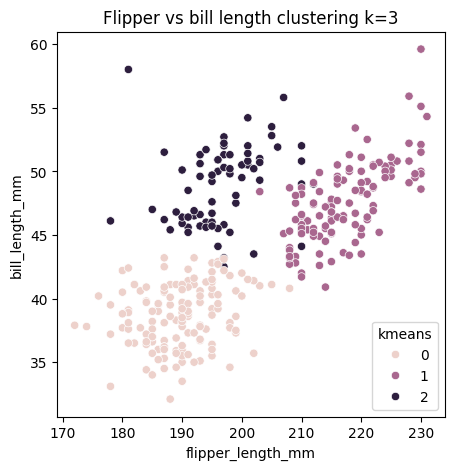

Adjusted Rand score: 0.9046436640041504


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,kmeans
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male,0
101,Adelie,Biscoe,41.0,20.0,203.0,4725.0,Male,0
102,Adelie,Biscoe,37.7,16.0,183.0,3075.0,Female,0
103,Adelie,Biscoe,37.8,20.0,190.0,4250.0,Male,0
104,Adelie,Biscoe,37.9,18.6,193.0,2925.0,Female,0
...,...,...,...,...,...,...,...,...
252,Gentoo,Biscoe,45.1,14.5,207.0,5050.0,Female,1
251,Gentoo,Biscoe,42.8,14.2,209.0,4700.0,Female,1
250,Gentoo,Biscoe,47.3,15.3,222.0,5250.0,Male,1
279,Gentoo,Biscoe,50.4,15.3,224.0,5550.0,Male,1


<Figure size 500x500 with 0 Axes>

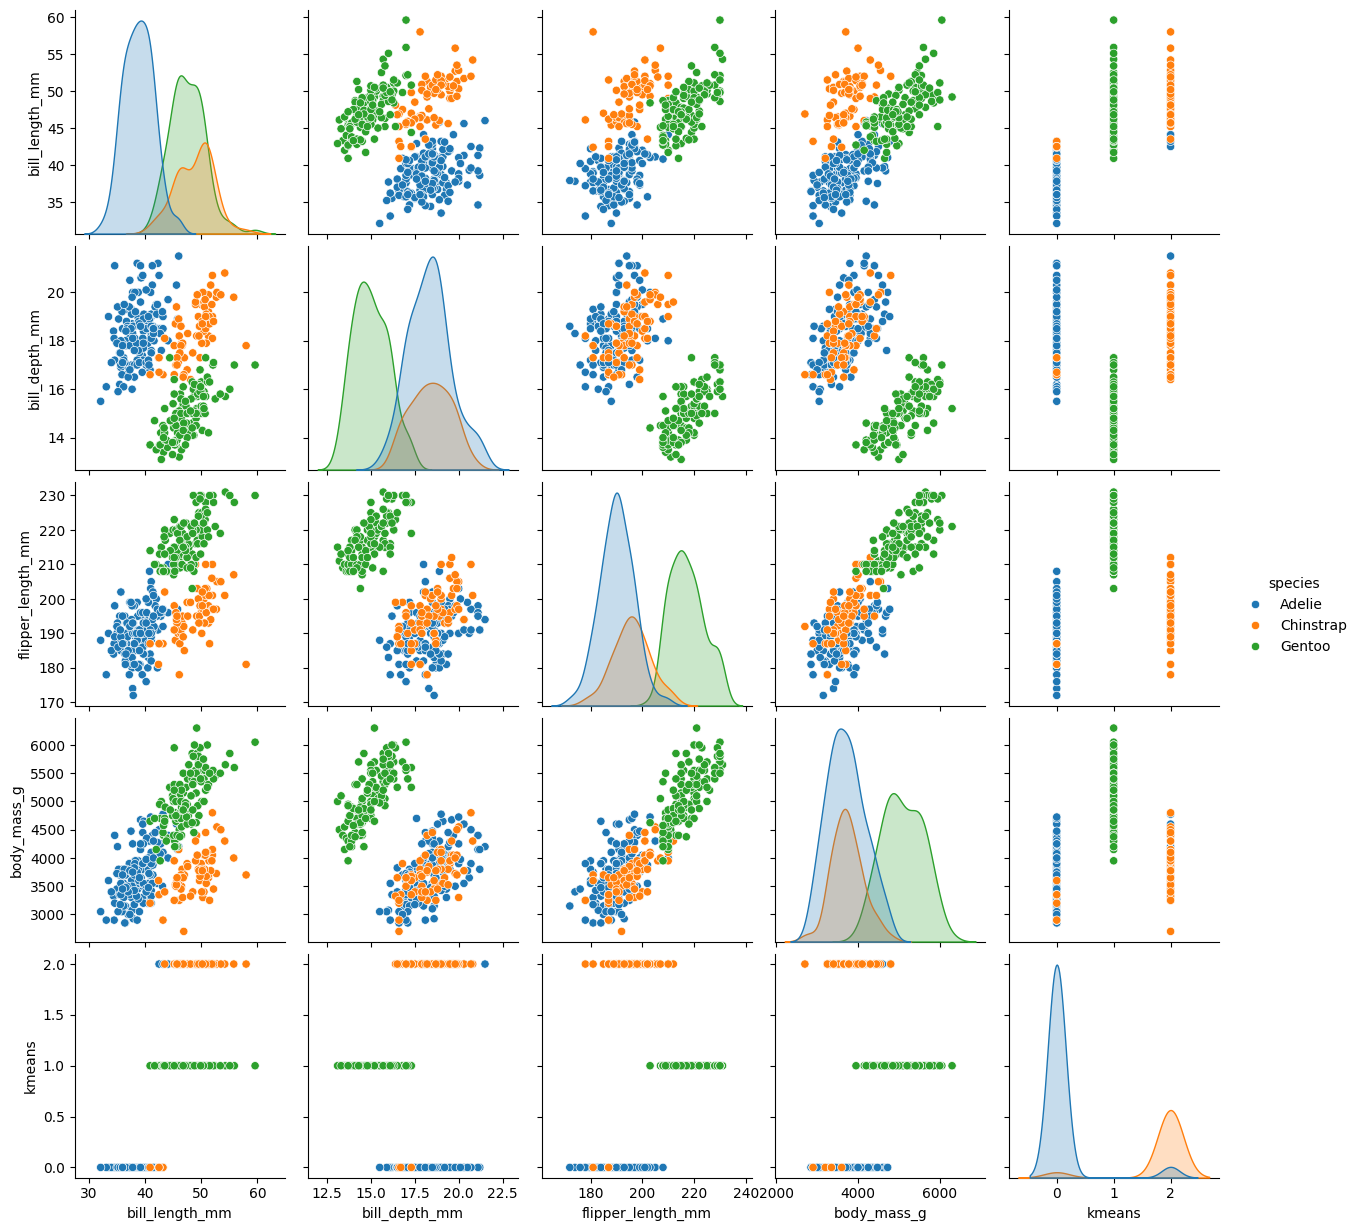

<Figure size 500x500 with 0 Axes>

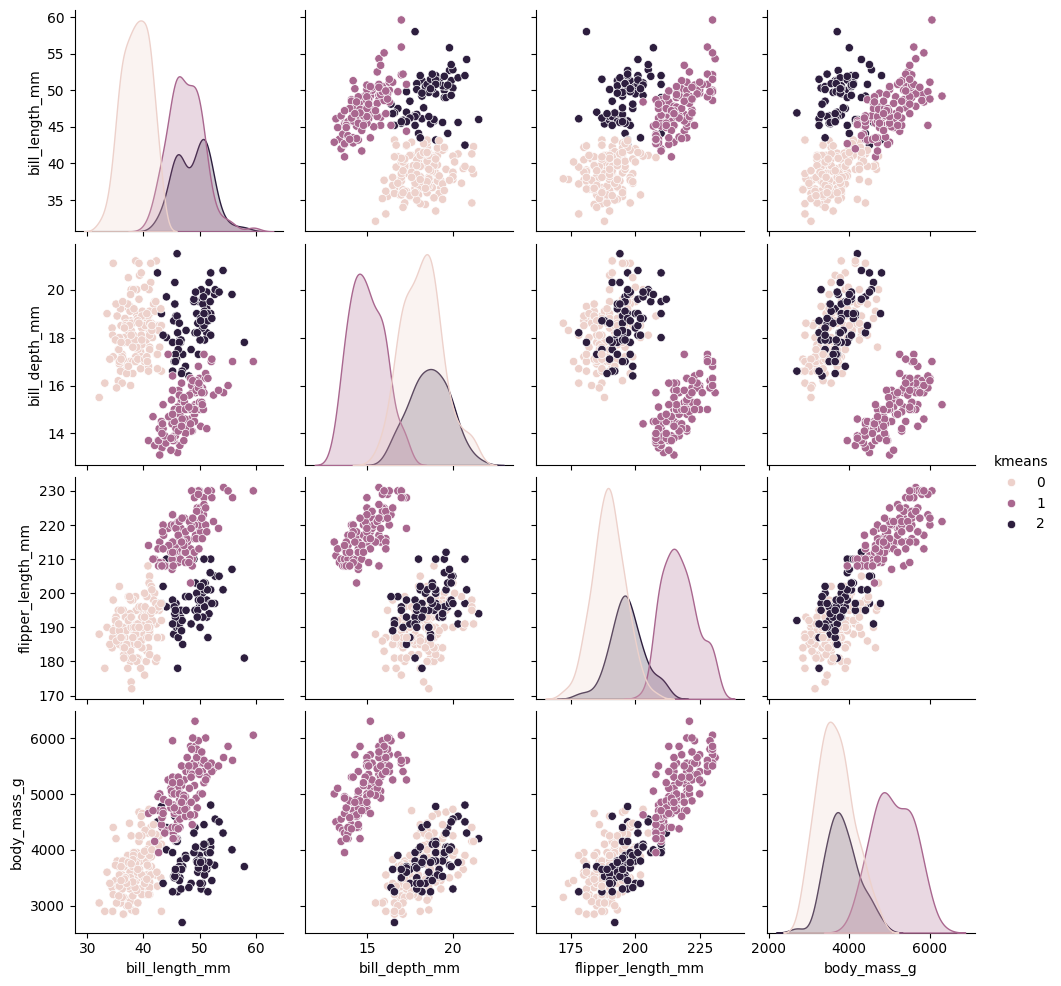

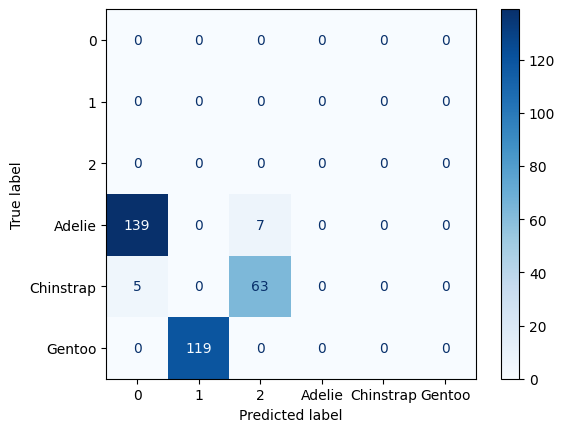

In [ ]:
from scipy import cluster
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
cols=['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g','sex']
# a) YOUR CODE HERE: check missing values per column, then dropna() and confirm the data is clean
for col in cols:
  penguins_missing = penguins.loc[penguins[col].isna()==True].shape[0]
  print('Missing values in ',col,':',penguins_missing)
penguins_clean=penguins.dropna()
print(penguins_clean)
for col in cols:
  penguins_missing = penguins_clean.loc[penguins_clean[col].isna()==True].shape[0]
  print('Missing values in ',col,':',penguins_missing)

# b) YOUR CODE HERE: normalize the numeric columns with StandardScaler
scaler=StandardScaler()
penguins_numdata=penguins_clean[num_cols]
penguins_scaled_df=pd.DataFrame(scaler.fit_transform(penguins_numdata),columns=penguins_numdata.columns,index=penguins_numdata.index)
print(penguins_scaled_df)
# c) YOUR CODE HERE: apply KMeans with n_clusters=3 on the normalized data
kmeans_labels = KMeans(n_clusters=3).fit_predict(penguins_scaled_df)
kmeans_result=KMeans(n_clusters=3).fit(penguins_scaled_df)
print('Cluster centroids {}'.format(kmeans_result.cluster_centers_))
print('Number of iterations required {}'.format(kmeans_result.n_iter_))
# d) YOUR CODE HERE: add kmeans_labels to penguins_clean, plot bill_length_mm vs flipper_length_mm colored by cluster,
#    and make two pairplots (one hue='species', one hue=kmeans cluster)
penguins_clean['kmeans']=kmeans_labels
plt.figure(figsize=(5,5))
ax = sns.scatterplot(x="flipper_length_mm", y="bill_length_mm", data=penguins_clean,hue='kmeans')
ax.set_title('Flipper vs bill length clustering k=3')
plt.show()
plt.figure(figsize=(5,5))
sns.pairplot(penguins_clean,hue="species")
plt.figure(figsize=(5,5))
sns.pairplot(penguins_clean,hue="kmeans")
# e) YOUR CODE HERE: confusion matrix and adjusted Rand score vs real 'species'
conf_matrix=confusion_matrix(penguins_clean['species'],penguins_clean['kmeans'].astype(str))
ConfusionMatrixDisplay.from_predictions(penguins_clean['species'],penguins_clean['kmeans'].astype(str),cmap='Blues')
rand_score=adjusted_rand_score(penguins_clean['species'],penguins_clean['kmeans'].astype(str))
print('Adjusted Rand score:',rand_score)
penguins_clean.sort_values(by=['species'])
# f) YOUR CODE HERE (as a comment or markdown cell): interpretation
#In general Kmeans recognise pretty well the different species (Randscore between 0.79-0.9) when used with normalised data.
#It has problem between Adelie and Chinstrap species when its data points for a same parameter has similar values since the euclidan distance does not diferentiate them anymore
#Normalizing the data improves the results since raw values has diferent scales that would mess the patron recognition

---

## **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

False
[[1 2]
 [1 4]
 [1 0]
 [5 6]
 [5 3]
 [5 0]]
5.656854249492381
5.656854249492381
agglo labels: [1 1 1 0 0 0]
kmeans labels [1 1 1 0 0 0]


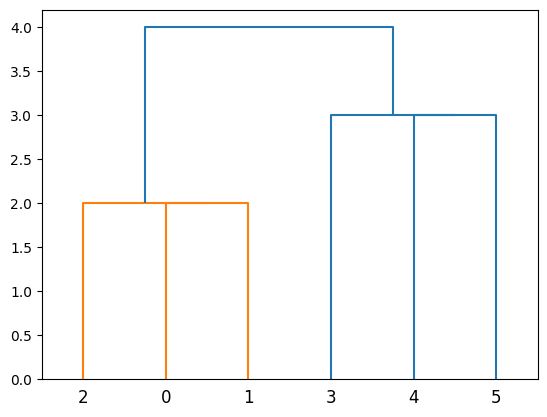

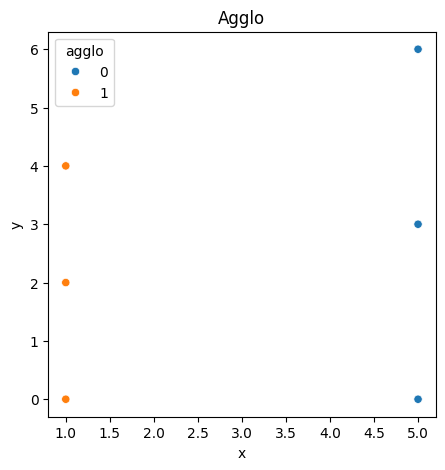

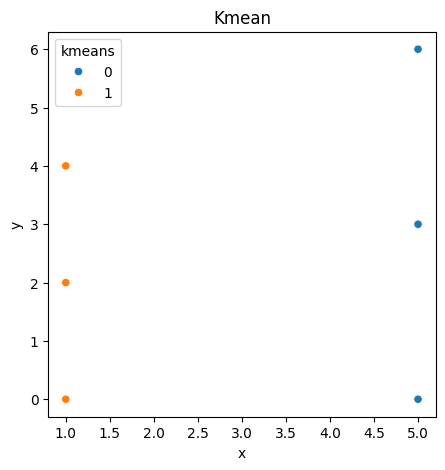

{np.int64(1): 3, np.int64(0): 3}
{np.int32(1): 3, np.int32(0): 3}


In [68]:
import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])

# a) YOUR CODE HERE: check for missing values with np.isnan(X).any()
print(np.isnan(X).any())
df_x=pd.DataFrame(X,columns=['x','y'])
# b) YOUR CODE HERE: normalize X with StandardScaler
scaler=StandardScaler()
X_scaled =scaler.fit_transform(X)
print(X)
# c) YOUR CODE HERE: plain-Python euclidean_distance function using a for loop (no numpy/sklearn)
def euclidean_distance(p1, p2):
    euc_dist=0
    a=0
    for i in range(len(p1)):
      euc_dist+=(p1[i]-p2[i])**2
    a=np.sqrt(euc_dist)
    return a

    pass

# test it
print(euclidean_distance(X[0], X[3]))
print(np.linalg.norm(X[0] - X[3]))

# d) YOUR CODE HERE: agglomerative clustering on X_scaled + dendrogram
clustering = AgglomerativeClustering(n_clusters=2).fit(X_scaled)
agglo_labels = clustering.labels_
Z = linkage(X)
dendrogram(Z)

# e) YOUR CODE HERE: k-means clustering with n_clusters=2 on X_scaled
kmeans_labels = KMeans(n_clusters=2).fit_predict(X_scaled)

# f) YOUR CODE HERE: compare both label arrays and make a side-by-side scatterplot
print('agglo labels:',agglo_labels)
print('kmeans labels',kmeans_labels)
df_x['agglo']=agglo_labels
df_x['kmeans']=kmeans_labels
ig = plt.figure(figsize=(5,5))
ax = sns.scatterplot(x="x", y="y", data=df_x,hue='agglo')
ax.set_title('Agglo')
plt.show()
ig2 = plt.figure(figsize=(5,5))
ax2 = sns.scatterplot(x="x", y="y", data=df_x,hue='kmeans')
ax2.set_title('Kmean')
plt.show()
#They're usually identical but at some iterations there is a difference since kmeans identify X[5] with the other cluster
#This is to be expected since kmeans can vary depending on the initial position of centroids and/or has problems with non-globular data
# g) YOUR CODE HERE: cluster_sizes function using a dictionary
def cluster_sizes(labels):
  count={}
  for label in labels:
    if label in count:
      count[label]+=1
    else:
      count[label]=1
  return count
pass

print(cluster_sizes(agglo_labels))
print(cluster_sizes(kmeans_labels))


---

## **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

       carat        cut color clarity  depth  table  price     x     y     z
1388    0.24      Ideal     G    VVS1   62.1   56.0    559  3.97  4.00  2.47
50052   0.58  Very Good     F    VVS2   60.0   57.0   2201  5.44  5.42  3.26
41645   0.40      Ideal     E    VVS2   62.1   55.0   1238  4.76  4.74  2.95
42377   0.43    Premium     E    VVS2   60.8   57.0   1304  4.92  4.89  2.98
17244   1.55      Ideal     E     SI2   62.3   55.0   6901  7.44  7.37  4.61
...      ...        ...   ...     ...    ...    ...    ...   ...   ...   ...
35207   0.33      Ideal     I      IF   61.6   55.0    891  4.47  4.46  2.75
15806   1.00      Ideal     E     SI1   62.4   55.0   6324  6.34  6.42  3.98
45884   0.58      Ideal     G     VS2   61.1   56.0   1719  5.40  5.43  3.31
22681   0.38      Ideal     J    VVS2   62.0   55.0    629  4.67  4.69  2.90
21429   1.18    Premium     G    VVS2   59.7   58.0   9537  6.94  6.90  4.13

[1000 rows x 10 columns]
       carat  depth  table  price     x     y     

/tmp/ipykernel_1075/2693486358.py:26: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  ax=sns.distplot(diamonds_clean["price"].values,bins=20)


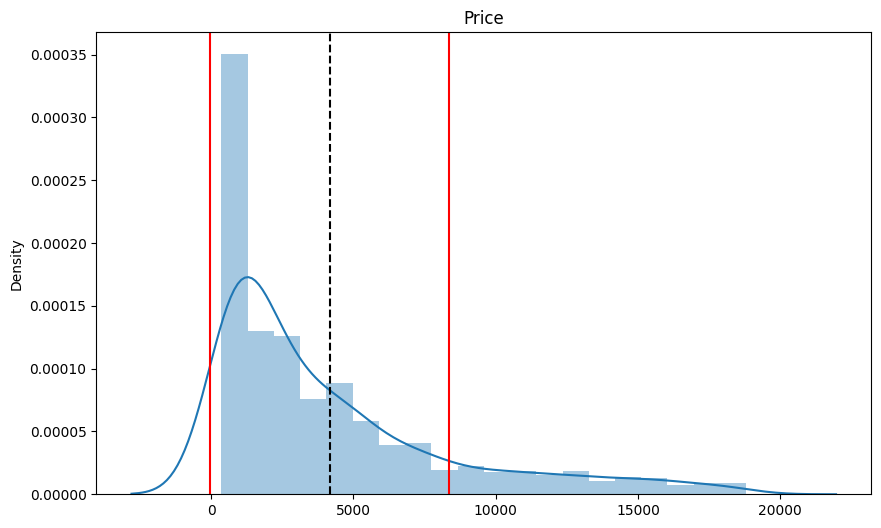

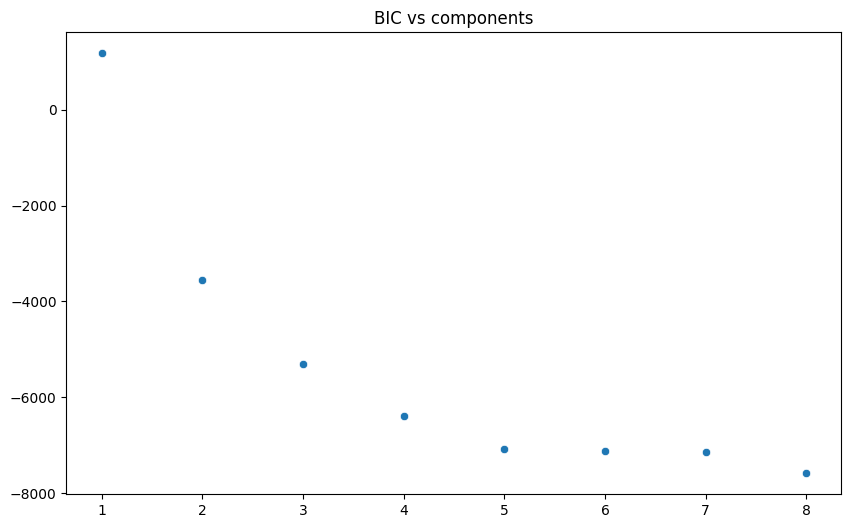

...and the winner is GMM model G = 8
[0 5 0 0 1 2 5 5 5 4 0 7 6 5 6 1 2 0 1 0 3 0 0 0 2 5 0 3 4 0 4 5 7 5 5 0 0
 5 5 7 5 5 0 3 5 0 1 1 3 4 0 1 5 4 4 4 4 0 2 5 2 0 3 4 0 0 5 5 5 5 4 0 4 7
 5 0 3 5 1 1 0 0 5 0 4 0 0 2 1 5 4 5 5 4 4 0 0 0 2 5 0 2 5 4 0 1 0 0 0 0 4
 0 6 5 2 4 7 2 5 5 4 7 4 7 0 0 0 0 0 2 0 4 0 0 0 0 0 4 5 2 4 2 0 7 2 0 4 1
 0 0 4 5 3 0 5 0 5 2 1 1 4 7 0 5 5 4 4 2 4 0 1 1 5 4 4 0 4 5 0 5 0 0 0 6 0
 5 2 0 0 0 1 5 0 4 3 4 0 4 4 4 0 4 0 5 0 5 5 2 0 4 0 3 1 2 0 6 5 4 7 5 4 0
 0 0 5 4 0 5 4 0 2 0 4 5 0 4 5 4 4 1 0 1 0 7 0 2 5 4 4 7 0 5 3 2 3 5 2 7 7
 7 0 0 6 2 4 0 0 1 4 3 0 4 5 2 4 5 5 0 5 0 5 4 1 0 0 0 0 5 1 4 0 0 1 5 4 4
 0 2 0 5 2 0 2 0 0 0 0 1 5 4 2 5 1 4 0 1 0 0 0 0 0 5 4 0 0 5 5 0 4 1 5 5 4
 7 2 4 1 5 2 5 7 1 2 4 0 0 0 1 5 5 4 0 5 7 0 0 4 1 0 5 4 5 0 2 4 4 4 4 0 5
 1 4 7 0 5 0 0 0 0 1 5 1 5 2 4 5 4 4 4 0 5 5 4 4 0 4 2 0 1 4 5 0 4 3 2 0 6
 5 3 1 0 0 4 4 2 5 1 0 4 0 4 0 4 5 5 0 3 5 4 0 4 4 0 5 4 0 0 2 4 2 0 3 0 5
 5 0 4 5 2 0 4 3 0 5 0 5 7 5 0 2 0 5 2 1 1 0 0 6 5 0 0 4 3 5 2 

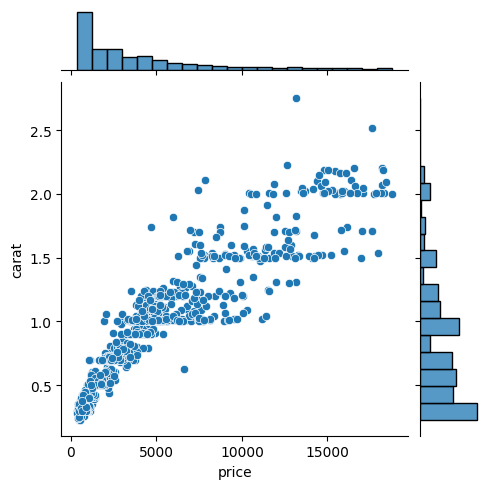

<Figure size 500x500 with 0 Axes>

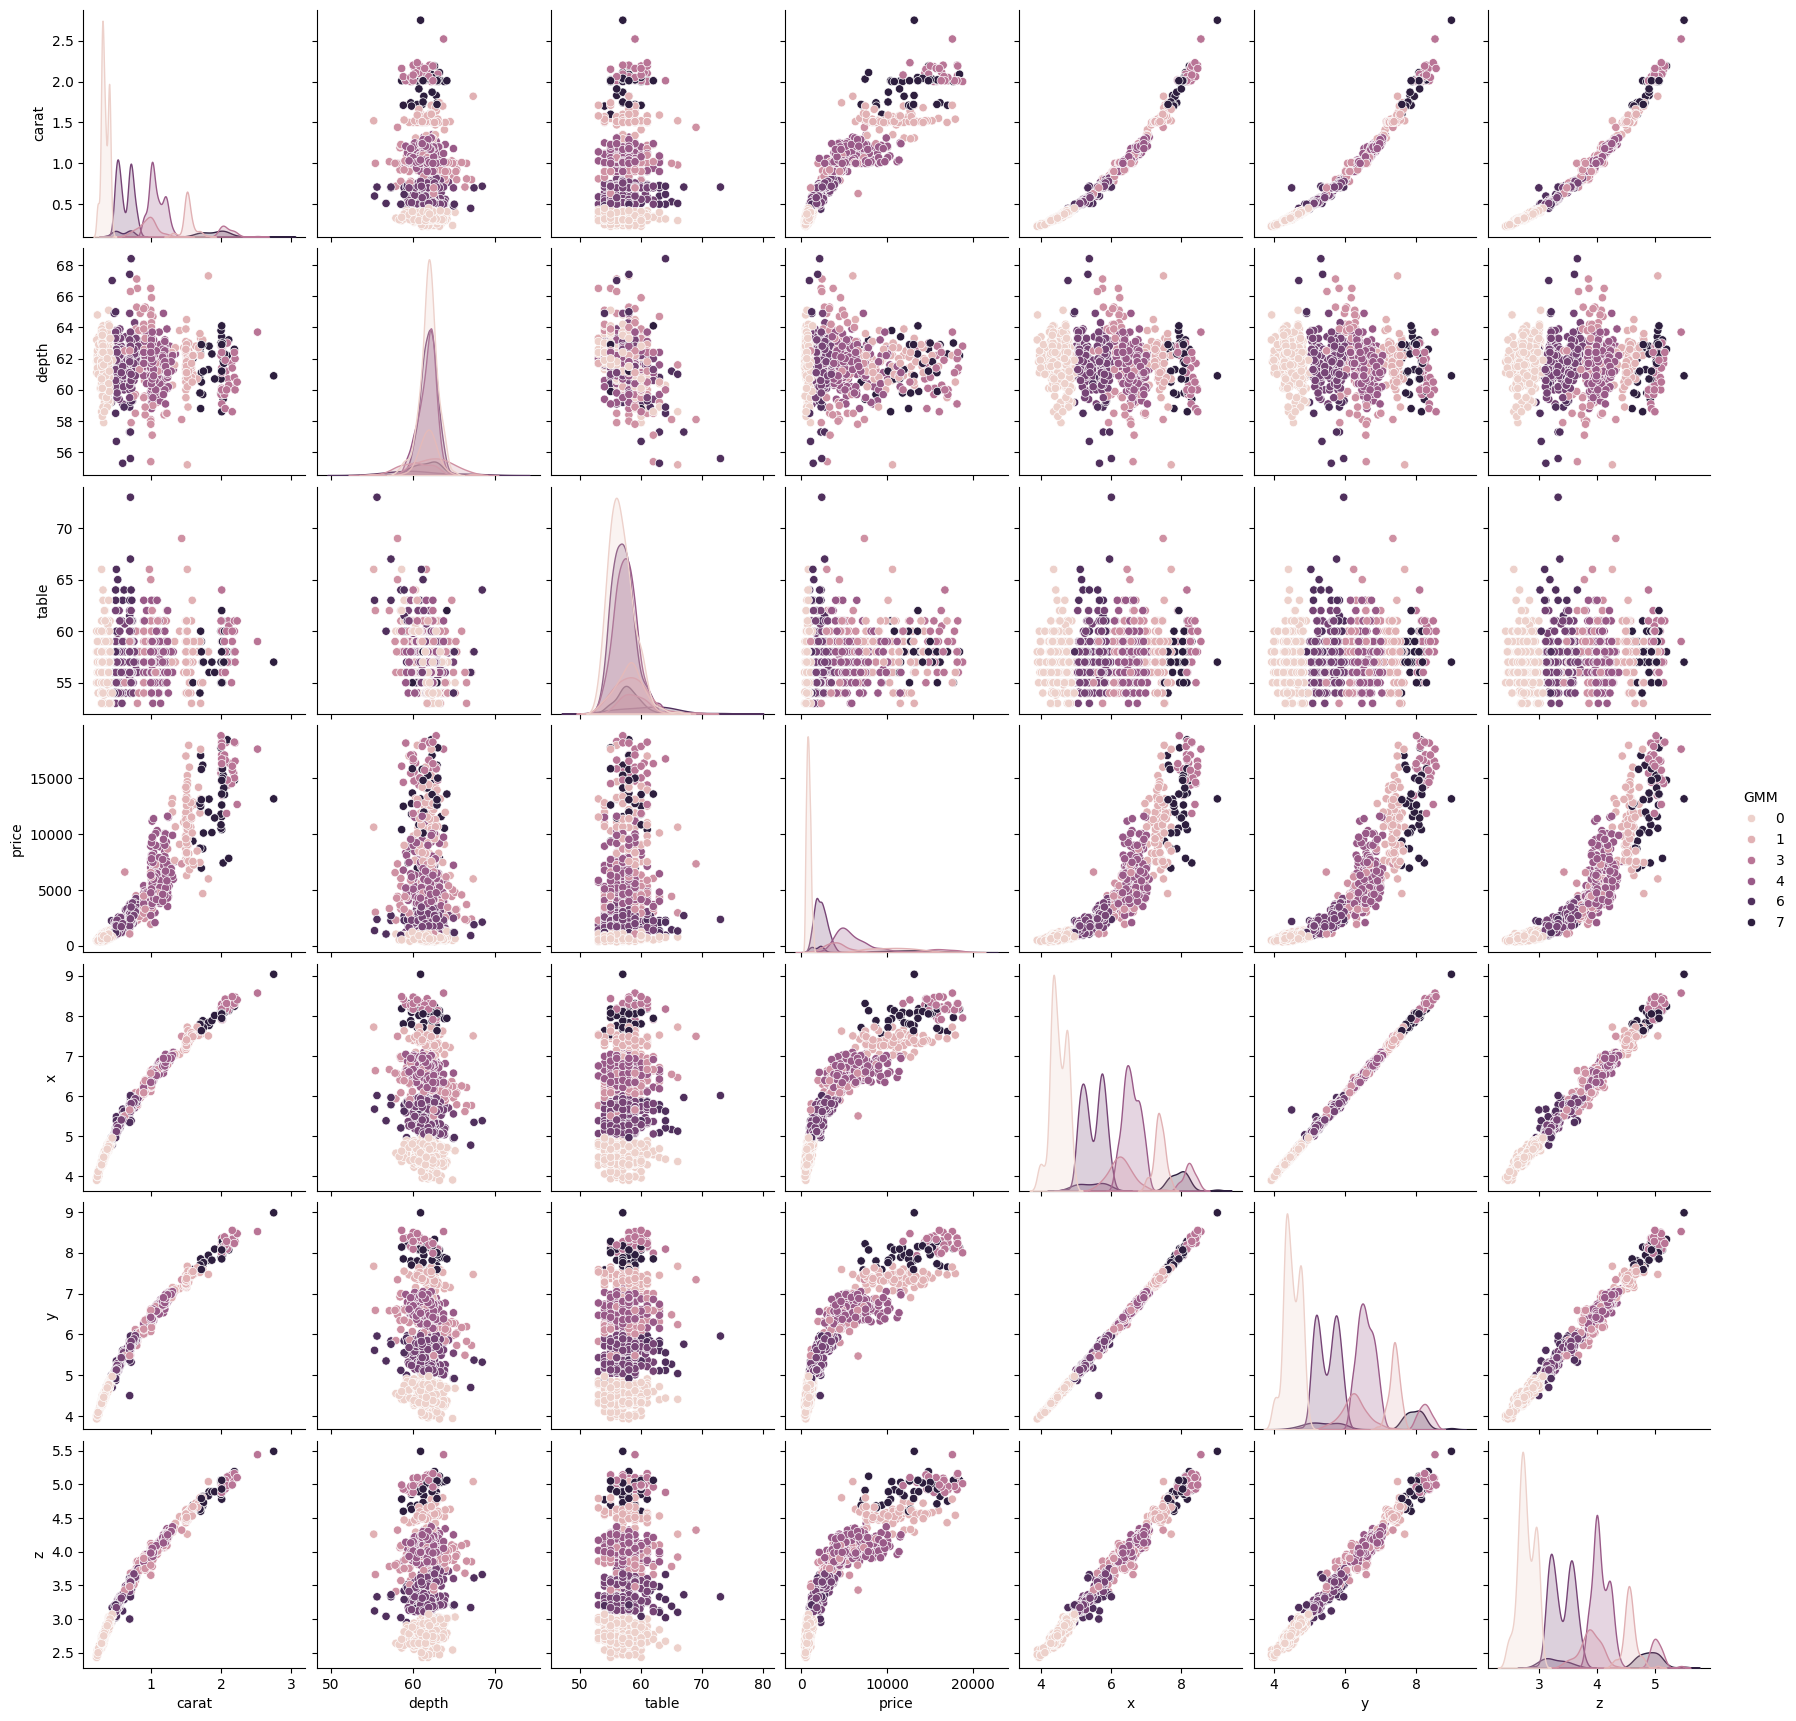

In [3]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
print(diamonds)
# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
diamonds_num = diamonds.select_dtypes(include=[np.number])
print(diamonds_num)
colum=list(diamonds_num.columns)
for col in colum:
  diamonds_missing = diamonds_num.loc[diamonds_num[col].isna()==True].shape[0]
  print('Missing values in ',col,':',diamonds_missing)
diamonds_clean=diamonds_num.dropna()
print(diamonds_clean)
for col in colum:
  diamonds_missing = diamonds_num.loc[diamonds_num[col].isna()==True].shape[0]
  print('Missing values in ',col,':',diamonds_missing)
# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines
std_price = diamonds_clean['price'].std()
media_price = diamonds_clean['price'].mean()
fig = plt.figure(figsize=(10,6))
ax=sns.distplot(diamonds_clean["price"].values,bins=20)
ax.set_title('Price')
plt.axvline(media_price, color="k", linestyle="--");
plt.axvline(media_price-std_price, color="r", linestyle="-");
plt.axvline(media_price+std_price, color="r", linestyle="-");


# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
scaler=StandardScaler()
diamonds_scaled=pd.DataFrame(scaler.fit_transform(diamonds_clean),columns=diamonds_clean.columns,index=diamonds_clean.index)
print(diamonds_scaled)

# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)
n_components=[]
for kG in n_components_range:
  gmm = mixture.GaussianMixture(n_components=kG,covariance_type='full').fit(diamonds_scaled)
  bic.append(gmm.bic(diamonds_scaled))
  n_components.append(kG)
fig = plt.figure(figsize=(10,6))
ax=sns.scatterplot(x=n_components,y=bic)
ax.set_title('BIC vs components')
plt.show()
# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM
best_n =np.argmin(bic)
print('...and the winner is GMM model G = {}'.format(best_n+1))
gmm = mixture.GaussianMixture(n_components=best_n+1,covariance_type='full').fit(diamonds_scaled)
gmm_labels = gmm.fit_predict(diamonds_clean)
print(gmm_labels)
# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)
diamonds_num['GMM']=gmm_labels
ax = sns.jointplot(x='price',y='carat',data=diamonds_num,height=5)
plt.figure(figsize=(5,5))
sns.pairplot(diamonds_num,hue="GMM")

# g) YOUR CODE HERE (as a comment or markdown cell): interpretation
#The number of clusters seems reasonable since the pairplot show a consistent behaviour of the clusters throught out the majority of plots representing coherent characteristics
#Looking at the pairplot only by eye I would not have guessed 8 clusters since the data point is to close to discern any clear cluster. Only when looking to the BIC vs component is evident to the eye the number of clusters
#Skipping the normalization of data does not change the number of clusters with minimal BIC,just altered a little the curve and made 6 clusters better than 7